# Beyond the Cage · Análisis de datos de la UFC masculina

Este cuaderno acompaña al simulador del sitio y responde preguntas concretas con datos reales de UFCStats
(dataset público `Greco1899/scrape_ufc_stats`). Todo se calcula con `pit.py`, que arma las características **punto en el tiempo**:
cada pelea usa solo lo que se sabía *antes* de que ocurriera.

**Preguntas**
0. ¿Qué tan bueno es el simulador? (backtest hacia adelante, contra líneas base)
1. ¿Cómo cambia la forma de terminar las peleas en cada división?
2. ¿Importa el alcance, una vez que se controla por el resto?
3. ¿Cómo pesa la edad?
4. ¿Qué estilos de pelea existen según los datos (clustering) y quién es quién?
5. ¿Qué estilos le ganan a cuáles?
6. ¿Cómo se ven los campeones actuales? (radar por división)

> Cómo reproducirlo: `pip install -r requirements.txt`, `python scripts/fetch_ufc_data.py` y abrir este cuaderno.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, ".")                      # el cuaderno vive en science/
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, Image, display
from scipy import stats
from sklearn.linear_model import LogisticRegression
import pit
from train_model import LABEL
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
RED, BLUE, GRAY = "#d71920", "#1d4fd7", "#8a8a8a"
DIV = pit.DIVS
out = pit.build(); F, CUR = out["fights"], out["current"]
F["year"] = F.date.dt.year
F["cat"] = np.where(F.method.str.startswith("KO"), "KO/TKO", np.where(F.method.str.startswith("SUB"), "Sumisión", np.where(F.method.str.startswith("DEC"), "Decisión", "Otro")))
F = F[F.year >= 2005].copy()
RES = {}
display(Markdown(f"**{len(F):,} peleas decisivas** ({F.date.min().date()} → {F.date.max().date()}) · datos hasta {out['dataThrough']}"))

**8,388 peleas decisivas** (2005-02-05 → 2026-10-31) · datos hasta 2026-10-31

## 0. ¿Qué tan bueno es el simulador? (backtest hacia adelante)

Cada año se predice usando **solo datos anteriores**. 4,427 peleas evaluadas (2018–2026). Menor log loss/Brier/ECE = mejor.

,Acierto,IC95% del acierto,Log loss,Brier,Error de calibración (ECE)
Modelo,,,,,
Azar (50/50),50.0%,50.0% – 50.0%,0.6931,0.2500,0.000
Solo Elo,55.4%,53.9% – 56.7%,0.6853,0.2461,0.008
Solo récord,57.6%,56.3% – 59.0%,0.6764,0.2418,0.015
Solo forma reciente,56.9%,55.4% – 58.3%,0.6785,0.2428,0.009
Simulador v1 (fórmula a mano),58.4%,57.0% – 59.9%,0.6865,0.2443,0.062
Modelo: regresión logística,61.9%,60.5% – 63.3%,0.6531,0.2306,0.014
Gradient boosting,60.1%,58.6% – 61.6%,0.6608,0.2342,0.013


- Modelo vs. azar: log loss -0.040 (IC95% -0.047 a -0.032).
- Modelo vs. simulador v1: log loss -0.033 (IC95% -0.042 a -0.024).
- El simulador v1 **no** se distingue del azar en log loss (IC95% de la diferencia: -0.018 a +0.006): acertaba más que el azar pero con probabilidades demasiado extremas.
- Gradient boosting no mejora a la regresión logística (diferencia +0.004 a +0.011): con tan pocos datos y tanto ruido, el modelo simple gana.

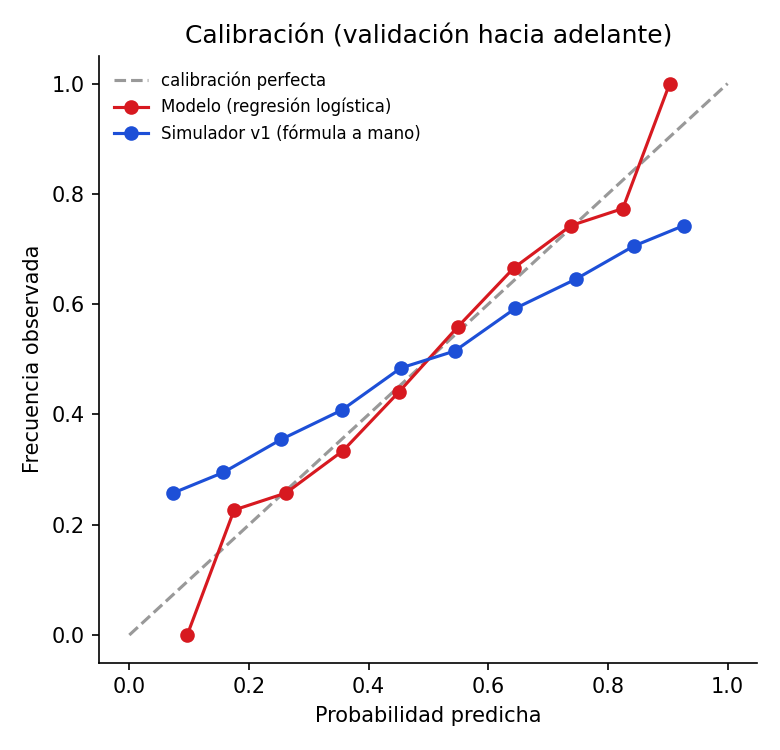

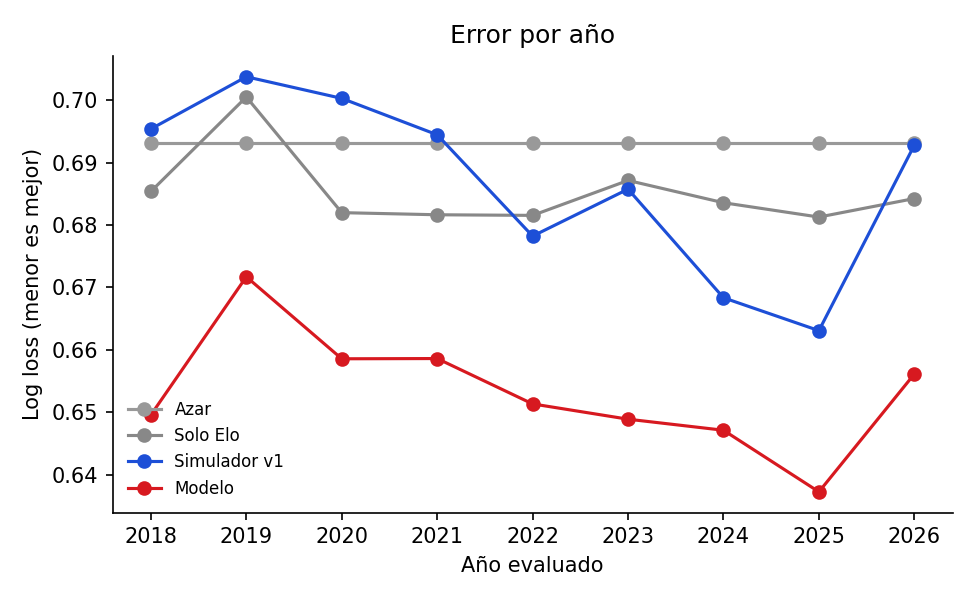

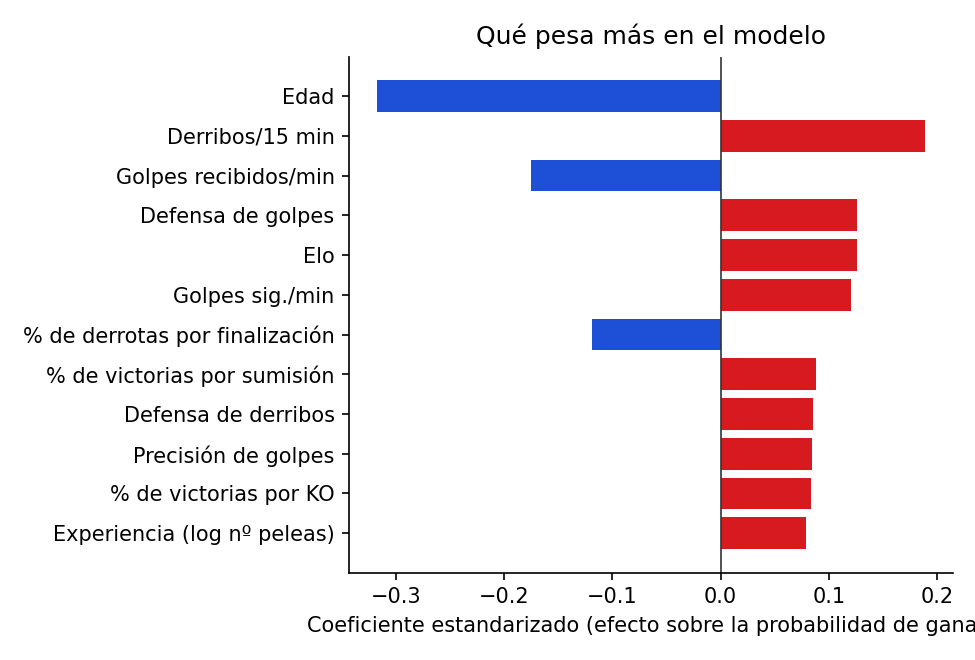

In [2]:
rep = json.load(open("../data/model_report.json", encoding="utf-8"))
nm = {"coin": "Azar (50/50)", "elo": "Solo Elo", "record": "Solo récord", "form": "Solo forma reciente", "heur": "Simulador v1 (fórmula a mano)", "lr": "Modelo: regresión logística", "gb": "Gradient boosting"}
tb = pd.DataFrame([{"Modelo": nm[k], "Acierto": f"{v['acc']:.1%}", "IC95% del acierto": f"{v['accCI'][0]:.1%} – {v['accCI'][1]:.1%}", "Log loss": round(v["ll"], 4),
                    "Brier": round(v["brier"], 4), "Error de calibración (ECE)": round(v["ece"], 3)} for k, v in rep["models"].items()]).set_index("Modelo")
display(Markdown(f"Cada año se predice usando **solo datos anteriores**. {rep['nTest']:,} peleas evaluadas ({rep['testFrom']}–{max(map(int, rep['byYear']))}). Menor log loss/Brier/ECE = mejor."))
display(tb)
d = rep["diffs"]
display(Markdown(f"- Modelo vs. azar: log loss {np.mean(d['lr_vs_coin']['ll']):+.3f} (IC95% {d['lr_vs_coin']['ll'][0]:+.3f} a {d['lr_vs_coin']['ll'][1]:+.3f}).\n"
                 f"- Modelo vs. simulador v1: log loss {np.mean(d['lr_vs_heur']['ll']):+.3f} (IC95% {d['lr_vs_heur']['ll'][0]:+.3f} a {d['lr_vs_heur']['ll'][1]:+.3f}).\n"
                 f"- El simulador v1 **no** se distingue del azar en log loss (IC95% de la diferencia: {d['heur_vs_coin']['ll'][0]:+.3f} a {d['heur_vs_coin']['ll'][1]:+.3f}): acertaba más que el azar pero con probabilidades demasiado extremas.\n"
                 f"- Gradient boosting no mejora a la regresión logística (diferencia {d['gb_vs_lr']['ll'][0]:+.3f} a {d['gb_vs_lr']['ll'][1]:+.3f}): con tan pocos datos y tanto ruido, el modelo simple gana."))
display(Image("figures/calibration.png", width=380)); display(Image("figures/by_year.png", width=470)); display(Image("figures/coefficients.png", width=520))
RES["lr"] = rep["models"]["lr"]; RES["heur"] = rep["models"]["heur"]

## 1. Tendencias por división
Tasa de finalización (KO/TKO o sumisión) por división y año, y forma de terminar las peleas.

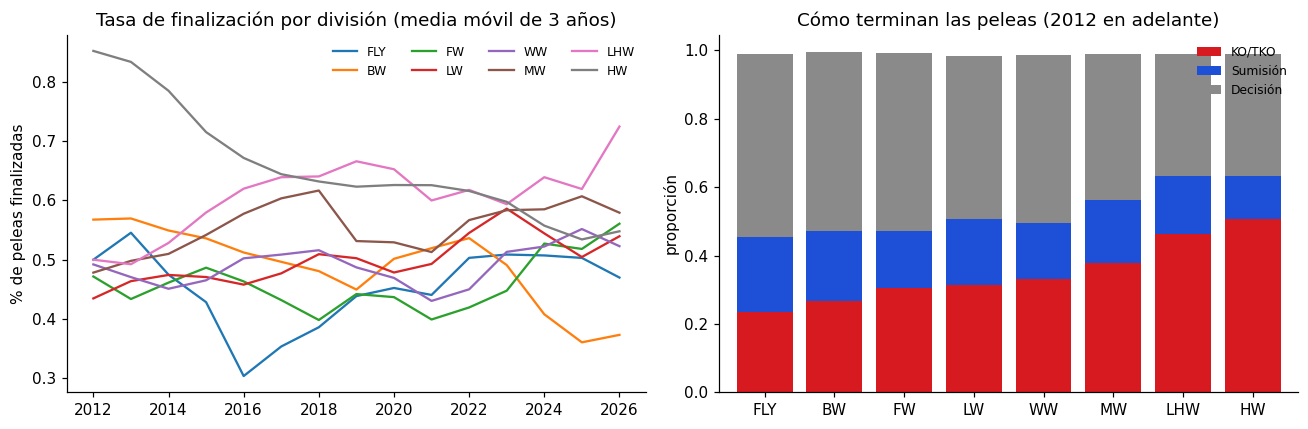

Más KO/TKO: **HW** (51%) · más decisiones: **FLY** (54%) · más sumisiones: **FLY** (22%).

In [3]:
D = F[F["div"] >= 0].copy(); D["fin"] = D.cat.isin(["KO/TKO", "Sumisión"])
g = D[D.year >= 2012].groupby(["year", "div"]).fin.mean().unstack()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for d in range(8): ax[0].plot(g.index, g[d].rolling(3, min_periods=1).mean(), label=DIV[d])
ax[0].set(title="Tasa de finalización por división (media móvil de 3 años)", ylabel="% de peleas finalizadas"); ax[0].legend(ncol=4, fontsize=8, frameon=False)
mix = D[D.year >= 2012].groupby("div").cat.value_counts(normalize=True).unstack()[["KO/TKO", "Sumisión", "Decisión"]]; mix.index = [DIV[i] for i in mix.index]
mix.plot.bar(stacked=True, ax=ax[1], color=[RED, BLUE, GRAY], width=.8, rot=0); ax[1].set(title="Cómo terminan las peleas (2012 en adelante)", ylabel="proporción"); ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
RES["ko_top"] = mix["KO/TKO"].idxmax(), mix["KO/TKO"].max(); RES["dec_top"] = mix["Decisión"].idxmax(), mix["Decisión"].max(); RES["sub_top"] = mix["Sumisión"].idxmax(), mix["Sumisión"].max()
display(Markdown(f"Más KO/TKO: **{RES['ko_top'][0]}** ({RES['ko_top'][1]:.0%}) · más decisiones: **{RES['dec_top'][0]}** ({RES['dec_top'][1]:.0%}) · más sumisiones: **{RES['sub_top'][0]}** ({RES['sub_top'][1]:.0%})."))

## 2. ¿Importa el alcance?
Primero la comparación cruda (¿gana más el de mayor alcance?) y después con controles (altura, edad, Elo y forma), que es lo que importa:
los de más alcance suelen ser más altos, y los mejores pueden tener más alcance por casualidad de la división.

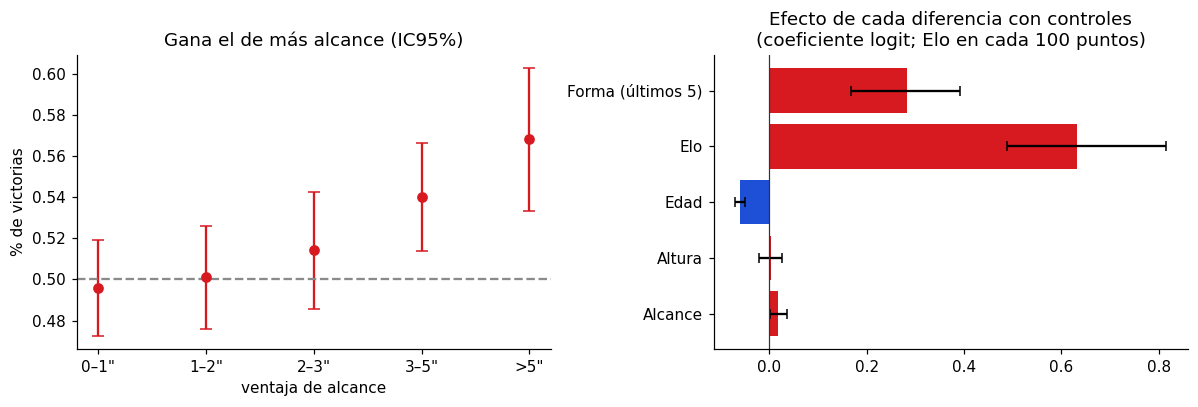

,ventaja de alcance,peleas,gana el de más alcance,lo,hi
0,"0–1""",1775,0.496,0.473,0.519
1,"1–2""",1549,0.501,0.476,0.526
2,"2–3""",1165,0.514,0.485,0.543
3,"3–5""",1362,0.540,0.514,0.567
4,">5""",781,0.569,0.534,0.603


Sin controles, gana el de más alcance en **51.8%** de 6,632 peleas. Con controles, cada pulgada extra de alcance equivale a ~**+0.5 puntos porcentuales** de probabilidad (coeficiente +0.019, IC95% +0.002 a +0.037).

In [4]:
R = F[(F.year >= 2010)].dropna(subset=["w_reach", "l_reach"]).copy(); R["d"] = R.w_reach - R.l_reach; R = R[R.d != 0]
bins = [(0, 1), (1, 2), (2, 3), (3, 5), (5, 30)]; rows = []
for lo, hi in bins:
    m = (R.d.abs() > lo) & (R.d.abs() <= hi); n = int(m.sum()); k = int((R.d[m] > 0).sum()); ci = stats.binomtest(k, n).proportion_ci(method="wilson")
    rows.append((f"{lo}–{hi}\"" if hi < 30 else f">{lo}\"", n, k / n, ci.low, ci.high))
T = pd.DataFrame(rows, columns=["ventaja de alcance", "peleas", "gana el de más alcance", "lo", "hi"])
raw_k, raw_n = int((R.d > 0).sum()), len(R); RES["reach_raw"] = raw_k / raw_n
# regresión con controles (sin penalización) y bootstrap
cols = ["reach", "height", "age", "elo", "form"]
Xd = np.column_stack([(R["w_" + c] - R["l_" + c]).values for c in cols]); Xd[:, 3] /= 100
def eff(X):
    m = LogisticRegression(C=1e6, fit_intercept=False, max_iter=2000).fit(np.vstack([X, -X]), np.r_[np.ones(len(X)), np.zeros(len(X))]); return m.coef_[0]
b0 = eff(Xd); rng = np.random.default_rng(0); bs = np.array([eff(Xd[rng.integers(0, len(Xd), len(Xd))]) for _ in range(300)])
RES["reach_coef"], RES["reach_ci"] = b0[0], np.percentile(bs[:, 0], [2.5, 97.5])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].errorbar(range(len(T)), T["gana el de más alcance"], yerr=[T["gana el de más alcance"] - T.lo, T.hi - T["gana el de más alcance"]], fmt="o", c=RED, capsize=4)
ax[0].axhline(.5, c=GRAY, ls="--"); ax[0].set_xticks(range(len(T))); ax[0].set_xticklabels(T["ventaja de alcance"]); ax[0].set(title="Gana el de más alcance (IC95%)", ylabel="% de victorias", xlabel="ventaja de alcance")
names = [LABEL[c] for c in cols]; ax[1].barh(names, b0, xerr=[b0 - np.percentile(bs, 2.5, 0), np.percentile(bs, 97.5, 0) - b0], color=[RED if v > 0 else BLUE for v in b0], capsize=3)
ax[1].axvline(0, c="#333", lw=.8); ax[1].set(title="Efecto de cada diferencia con controles\n(coeficiente logit; Elo en cada 100 puntos)")
plt.tight_layout(); plt.show(); display(T.round(3))
pp = RES["reach_coef"] / 4
display(Markdown(f"Sin controles, gana el de más alcance en **{RES['reach_raw']:.1%}** de {raw_n:,} peleas. Con controles, cada pulgada extra de alcance equivale a ~**{pp * 100:+.1f} puntos porcentuales** "
                 f"de probabilidad (coeficiente {RES['reach_coef']:+.3f}, IC95% {RES['reach_ci'][0]:+.3f} a {RES['reach_ci'][1]:+.3f})."))

## 3. ¿Cómo pesa la edad?
Dos miradas: (a) ¿gana más el más joven? y (b) cuánto rinden los peleadores *por encima o por debajo de lo que dice su Elo* según su edad
(un valor negativo significa que pierden más de lo esperado).

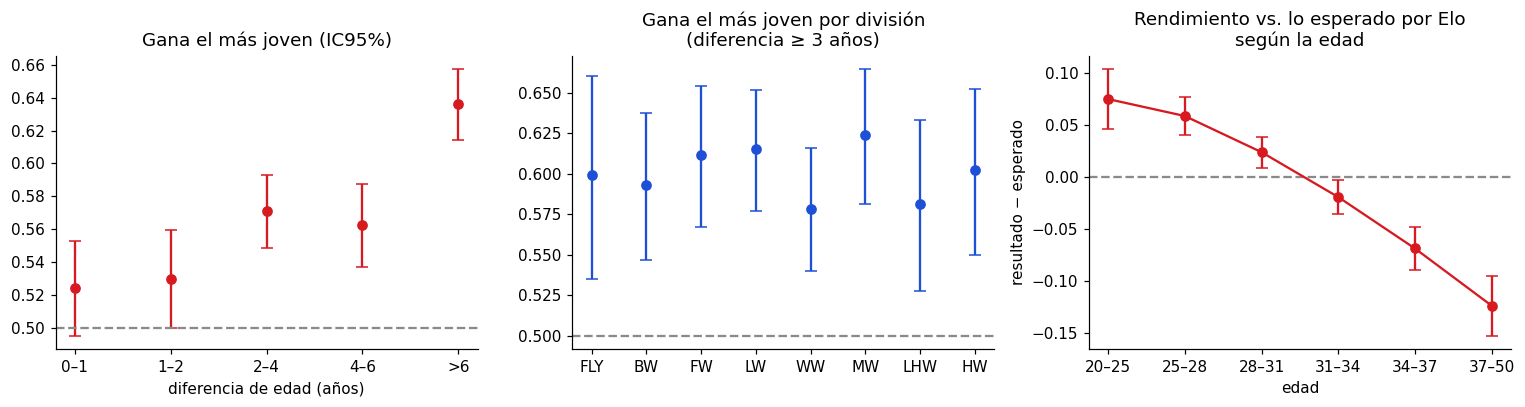

,diferencia de edad (años),peleas,gana el más joven,lo,hi
0,0–1,1146,0.524,0.495,0.553
1,1–2,1087,0.530,0.500,0.559
2,2–4,1949,0.571,0.549,0.593
3,4–6,1463,0.563,0.537,0.588
4,>6,1921,0.636,0.614,0.657


Con 3 o más años de diferencia gana el más joven el **60.2%** de las veces (4,236 peleas). A los 37–50 años el resultado está **-0.124** respecto de lo esperado por Elo.

In [5]:
A = F[F.year >= 2010].copy(); A["d"] = A.l_age - A.w_age                 # > 0: el ganador era más joven
A = A[A.d != 0]; bins = [(0, 1), (1, 2), (2, 4), (4, 6), (6, 30)]; rows = []
for lo, hi in bins:
    m = (A.d.abs() > lo) & (A.d.abs() <= hi); n = int(m.sum()); k = int((A.d[m] > 0).sum()); ci = stats.binomtest(k, n).proportion_ci(method="wilson")
    rows.append((f"{lo}–{hi}" if hi < 30 else f">{lo}", n, k / n, ci.low, ci.high))
TA = pd.DataFrame(rows, columns=["diferencia de edad (años)", "peleas", "gana el más joven", "lo", "hi"])
big = A[A.d.abs() >= 3]; byd = []
for d in range(8):
    x = big[big["div"] == d]; k = int((x.d > 0).sum()); n = len(x); ci = stats.binomtest(k, n).proportion_ci(method="wilson"); byd.append((DIV[d], n, k / n, ci.low, ci.high))
BD = pd.DataFrame(byd, columns=["div", "n", "p", "lo", "hi"])
# rendimiento vs. Elo según edad
E = 1 / (1 + 10 ** ((A.l_elo - A.w_elo) / 400)); s = pd.concat([pd.DataFrame({"age": A.w_age, "res": 1 - E}), pd.DataFrame({"age": A.l_age, "res": -(1 - E)})])
s["bin"] = pd.cut(s.age, [20, 25, 28, 31, 34, 37, 50]); cv = s.groupby("bin", observed=True).res.agg(["mean", "sem", "count"])
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].errorbar(range(len(TA)), TA["gana el más joven"], yerr=[TA["gana el más joven"] - TA.lo, TA.hi - TA["gana el más joven"]], fmt="o", c=RED, capsize=4); ax[0].axhline(.5, c=GRAY, ls="--")
ax[0].set_xticks(range(len(TA))); ax[0].set_xticklabels(TA["diferencia de edad (años)"]); ax[0].set(title="Gana el más joven (IC95%)", xlabel="diferencia de edad (años)")
ax[1].errorbar(range(len(BD)), BD.p, yerr=[BD.p - BD.lo, BD.hi - BD.p], fmt="o", c=BLUE, capsize=4); ax[1].axhline(.5, c=GRAY, ls="--"); ax[1].set_xticks(range(8)); ax[1].set_xticklabels(BD["div"])
ax[1].set(title="Gana el más joven por división\n(diferencia ≥ 3 años)")
ax[2].errorbar(range(len(cv)), cv["mean"], yerr=1.96 * cv["sem"], fmt="o-", c=RED, capsize=4); ax[2].axhline(0, c=GRAY, ls="--"); ax[2].set_xticks(range(len(cv))); ax[2].set_xticklabels([f"{int(i.left)}–{int(i.right)}" for i in cv.index])
ax[2].set(title="Rendimiento vs. lo esperado por Elo\nsegún la edad", xlabel="edad", ylabel="resultado − esperado")
plt.tight_layout(); plt.show(); display(TA.round(3))
RES["young_big"] = float((big.d > 0).mean()); RES["young_n"] = len(big); RES["age_old"] = cv["mean"].iloc[-1]; RES["age_old_lbl"] = f"{int(cv.index[-1].left)}–{int(cv.index[-1].right)}"; RES["age_young"] = cv["mean"].iloc[1]
display(Markdown(f"Con 3 o más años de diferencia gana el más joven el **{RES['young_big']:.1%}** de las veces ({RES['young_n']:,} peleas). A los {RES['age_old_lbl']} años el resultado está **{RES['age_old']:+.3f}** respecto de lo esperado por Elo."))

## 4. Estilos de pelea según los datos (clustering)
Se agrupan peleadores activos por su perfil de golpeo, grappling y finalización. Importante: cada métrica se **estandariza dentro de su división**,
para que agrupe por estilo y no por peso.

Silhouette por número de grupos: k=3: 0.124, k=4: 0.120, k=5: 0.119, k=6: 0.117, k=7: 0.113, k=8: 0.103. Se elige k=5 como compromiso entre interpretabilidad y separación (las diferencias entre k son chicas: los estilos forman un continuo, no islas).

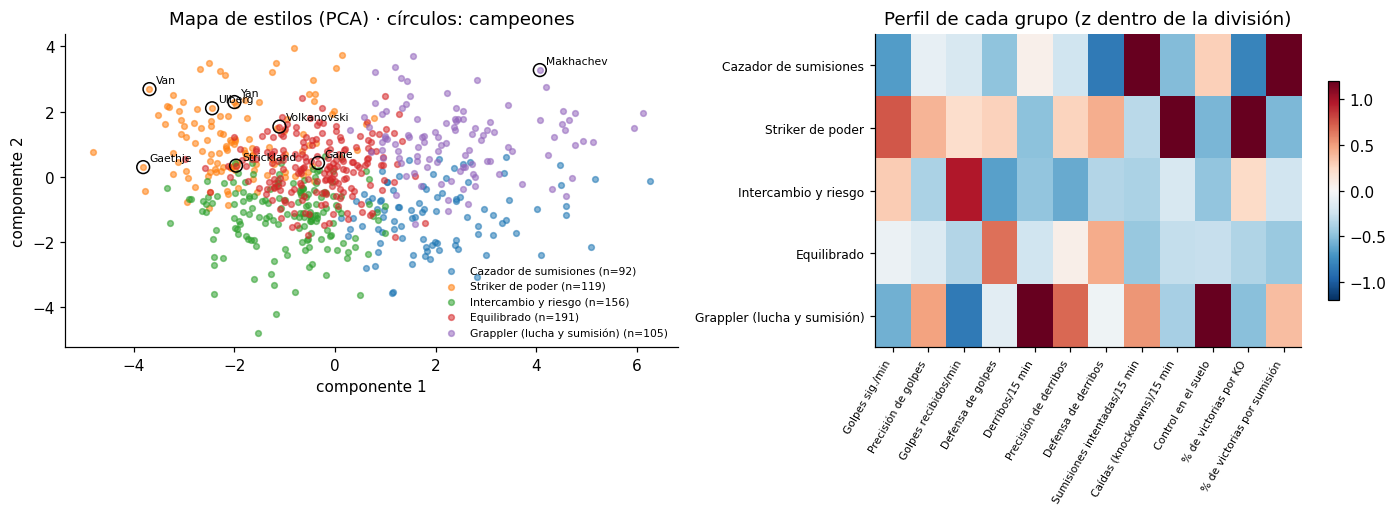

Perfiles estadísticos asignados a **126 de los 128** peleadores del sitio (`data/styles.json`); el resto no tiene datos suficientes o está inactivo.

In [6]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
FEAT = ["slpm", "acc", "sapm", "def", "tdavg", "tdacc", "tddef", "sub15", "kd15", "ctrl15", "ko_rate", "sub_rate"]
ref = pd.Timestamp(out["dataThrough"]).date()
P = CUR[(CUR.nst >= 3) & (CUR["min"] >= 15) & (CUR.ldiv >= 0) & CUR["last"].apply(lambda x: x is not None and (ref - x).days < 4 * 365)].copy()
Z = P[FEAT].copy()
for d, g in P.groupby("ldiv"): Z.loc[g.index] = (g[FEAT] - g[FEAT].mean()) / g[FEAT].std()
sil = {k: silhouette_score(Z, KMeans(k, n_init=10, random_state=0).fit_predict(Z)) for k in range(3, 9)}
display(Markdown("Silhouette por número de grupos: " + ", ".join(f"k={k}: {v:.3f}" for k, v in sil.items()) + ". Se elige k=5 como compromiso entre interpretabilidad y separación (las diferencias entre k son chicas: los estilos forman un continuo, no islas)."))
K = 5; km = KMeans(K, n_init=20, random_state=0).fit(Z); P["cl"] = km.labels_; Z["cl"] = km.labels_
prof = Z.groupby("cl")[FEAT].mean()
def lab(z):
    st, gr, sb = z[["slpm", "acc", "kd15", "ko_rate"]].mean(), z[["tdavg", "ctrl15", "tdacc"]].mean(), z[["sub15", "sub_rate"]].mean(); df = (z[["def", "tddef"]].mean() - z["sapm"]) / 2
    if gr > .35 and sb > .35: return ("Grappler (lucha y sumisión)", "Grappler (wrestling & subs)")
    if gr > .35: return ("Luchador de control", "Control wrestler")
    if st > .35 and df > .15: return ("Striker técnico", "Technical striker")
    if st > .35: return ("Striker de poder", "Power striker")
    if sb > .45: return ("Cazador de sumisiones", "Submission hunter")
    if df < -.25: return ("Intercambio y riesgo", "Brawler, high risk")
    return ("Equilibrado", "Well-rounded")
L = {c: lab(prof.loc[c]) for c in prof.index}
seen = {}
for c in L:
    seen[L[c]] = seen.get(L[c], 0) + 1
    if seen[L[c]] > 1: L[c] = (L[c][0] + f" {seen[L[c]]}", L[c][1] + f" {seen[L[c]]}")
P["style"] = P.cl.map(lambda c: L[c][0])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})
pc = PCA(2, random_state=0).fit(Z[FEAT]); XY = pc.transform(Z[FEAT]); cmap = plt.get_cmap("tab10")
for c in prof.index: m = (P.cl == c).values; ax[0].scatter(XY[m, 0], XY[m, 1], s=14, alpha=.55, color=cmap(c), label=f"{L[c][0]} (n={m.sum()})")
rk = json.load(open("../data/rankings.json", encoding="utf-8")); al = json.load(open("../data/aliases.json", encoding="utf-8"))
def rid(n):
    n = al.get(n, n); i = out["ids"].get(pit.key(n))
    return i if i is not None else next((j for j, x in enumerate(out["names"]) if pit.short(x) == pit.short(n)), None)
for d, lst in rk["divisions"].items():
    i = rid(lst[0]["n"])
    if i in P.index: j = list(P.index).index(i); ax[0].scatter(*XY[j], s=70, facecolors="none", edgecolors="k"); ax[0].annotate(lst[0]["n"].split()[-1], XY[j], fontsize=7, xytext=(4, 4), textcoords="offset points")
ax[0].set(title="Mapa de estilos (PCA) · círculos: campeones", xlabel="componente 1", ylabel="componente 2"); ax[0].legend(fontsize=7, frameon=False)
im = ax[1].imshow(prof.values, cmap="RdBu_r", vmin=-1.2, vmax=1.2, aspect="auto"); ax[1].set_xticks(range(len(FEAT))); ax[1].set_xticklabels([LABEL[f] for f in FEAT], rotation=60, ha="right", fontsize=7)
ax[1].set_yticks(range(len(prof))); ax[1].set_yticklabels([L[c][0] for c in prof.index], fontsize=8); ax[1].set_title("Perfil de cada grupo (z dentro de la división)"); plt.colorbar(im, ax=ax[1], shrink=.7)
plt.tight_layout(); plt.savefig("figures/clusters.png", dpi=150); plt.show()
styles = {}
for d, lst in rk["divisions"].items():
    for f in lst:
        i = rid(f["n"])
        if i in P.index: styles[f["n"]] = list(L[P.loc[i, "cl"]])
json.dump(styles, open("../data/styles.json", "w", encoding="utf-8"), ensure_ascii=False, separators=(",", ":"))
RES["sil"] = sil[K]; RES["clusters"] = {L[c][0]: int((P.cl == c).sum()) for c in prof.index}; RES["styled"] = len(styles)
display(Markdown(f"Perfiles estadísticos asignados a **{len(styles)} de los 128** peleadores del sitio (`data/styles.json`); el resto no tiene datos suficientes o está inactivo."))

## 5. ¿Qué estilos le ganan a cuáles?
Win rate de cada estilo (fila) contra cada otro (columna) en peleas desde 2012 en las que ambos peleadores tienen perfil.
*Limitación:* los grupos usan estadísticas de toda la carrera hasta hoy, que incluyen la propia pelea: es un análisis descriptivo, no predictivo.

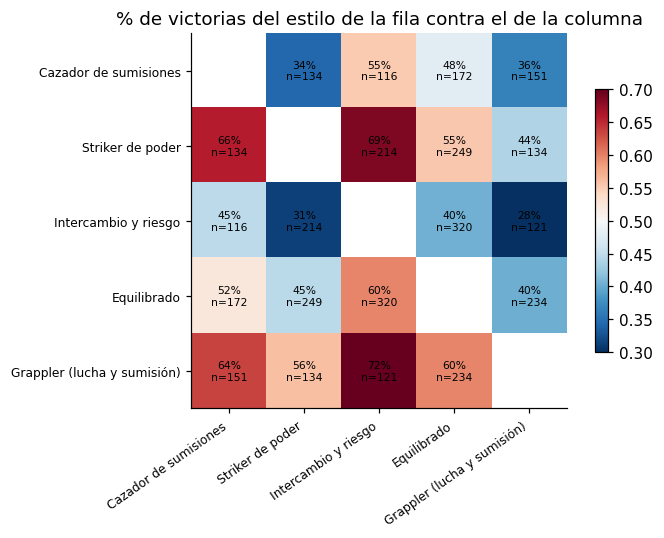

Mayor ventaja observada: **Grappler (lucha y sumisión)** le gana a **Intercambio y riesgo** el 72% de las veces (n=121, IC95% 63%–79%). Con tantas combinaciones, algunas diferencias aparecen por azar: hay que leerlas con el intervalo, no con el punto.

In [7]:
cl = P.cl.to_dict(); G = F[(F.year >= 2012)].copy()
G["cw"] = G.w.map(lambda n: cl.get(out["ids"].get(pit.key(n)))); G["cl_"] = G.l.map(lambda n: cl.get(out["ids"].get(pit.key(n))))
G = G.dropna(subset=["cw", "cl_"]); G = G[G.cw != G.cl_]
W = np.zeros((K, K)); 
for a, b in zip(G.cw.astype(int), G.cl_.astype(int)): W[a, b] += 1
rate = np.where(W + W.T >= 25, W / np.maximum(W + W.T, 1), np.nan)
fig, ax = plt.subplots(figsize=(6.8, 5)); im = ax.imshow(rate, cmap="RdBu_r", vmin=.3, vmax=.7)
for i in range(K):
    for j in range(K):
        if i != j and not np.isnan(rate[i, j]): ax.text(j, i, f"{rate[i, j]:.0%}\nn={int(W[i, j] + W[j, i])}", ha="center", va="center", fontsize=7)
ax.set_xticks(range(K)); ax.set_xticklabels([L[c][0] for c in range(K)], rotation=35, ha="right", fontsize=8); ax.set_yticks(range(K)); ax.set_yticklabels([L[c][0] for c in range(K)], fontsize=8)
ax.set(title="% de victorias del estilo de la fila contra el de la columna"); plt.colorbar(im, shrink=.7); plt.tight_layout(); plt.savefig("figures/style_matchups.png", dpi=150); plt.show()
best = max(((rate[i, j], i, j, int(W[i, j] + W[j, i])) for i in range(K) for j in range(K) if i != j and not np.isnan(rate[i, j])), default=None)
if best:
    k_, n_ = int(W[best[1], best[2]]), best[3]; ci = stats.binomtest(k_, n_).proportion_ci(method="wilson"); RES["match"] = (L[best[1]][0], L[best[2]][0], best[0], n_, ci.low, ci.high)
    display(Markdown(f"Mayor ventaja observada: **{RES['match'][0]}** le gana a **{RES['match'][1]}** el {RES['match'][2]:.0%} de las veces (n={RES['match'][3]}, IC95% {RES['match'][4]:.0%}–{RES['match'][5]:.0%}). "
                     "Con tantas combinaciones, algunas diferencias aparecen por azar: hay que leerlas con el intervalo, no con el punto."))

## 6. Campeones actuales: radar por división
Las valoraciones 0–99 del sitio, calculadas como percentil dentro de cada división (por eso son comparables entre pesos).

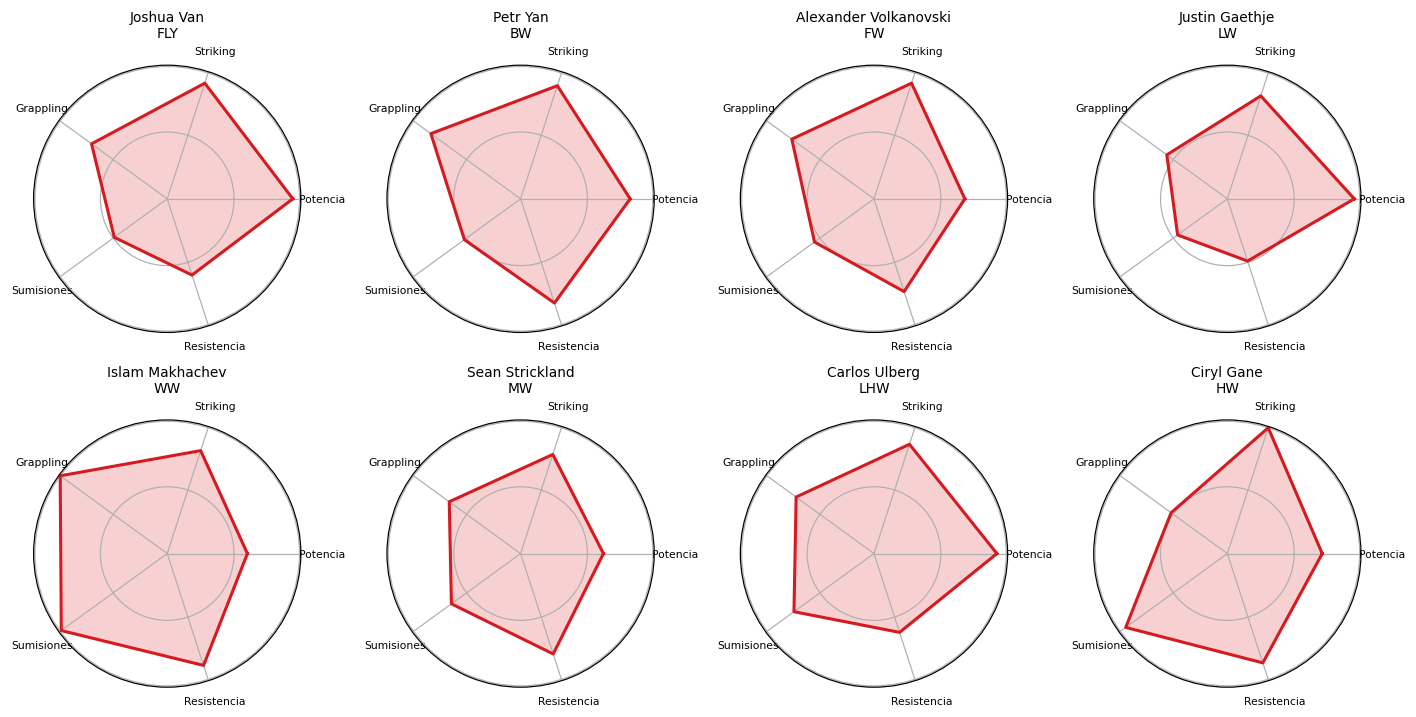

In [8]:
FJ = json.load(open("../data/fighters.json", encoding="utf-8"))["fighters"]; champs = [f for f in FJ if f["k"] == 0]
ax_names = ["Potencia", "Striking", "Grappling", "Sumisiones", "Resistencia"]; ang = np.linspace(0, 2 * np.pi, 5, endpoint=False).tolist(); ang += ang[:1]
fig, axs = plt.subplots(2, 4, figsize=(13, 6.6), subplot_kw={"polar": True})
for a, f in zip(axs.flat, champs):
    v = [f[k] for k in "PSGBR"]; v += v[:1]; a.plot(ang, v, c=RED, lw=2); a.fill(ang, v, color=RED, alpha=.2); a.set_ylim(0, 100); a.set_yticks([50, 99]); a.set_yticklabels([])
    a.set_xticks(ang[:-1]); a.set_xticklabels(ax_names, fontsize=7); a.set_title(f"{f['n']}\n{DIV[f['d']]}", fontsize=9)
plt.tight_layout(); plt.savefig("figures/radar_champions.png", dpi=150); plt.show()

## 7. Conclusiones

In [9]:
c = RES; m = c.get("match")
lines = [
 f"**Simulador.** El modelo entrenado acierta **{c['lr']['acc']:.1%}** (IC95% {c['lr']['accCI'][0]:.1%}–{c['lr']['accCI'][1]:.1%}) contra {c['heur']['acc']:.1%} del simulador v1 y 50% del azar, y está bien calibrado (ECE {c['lr']['ece']:.3f} vs {c['heur']['ece']:.3f}). "
 "El v1 acertaba más que el azar pero con probabilidades demasiado extremas, por eso su log loss no mejora al del azar.",
 f"**Techo realista.** Predecir peleas es ruidoso: ~{c['lr']['acc']:.0%} de acierto es lo que logra este modelo con estos datos públicos; no incluye lesiones, campamentos ni preparación específica.",
 f"**Edad.** Es el factor más fuerte del modelo: con 3 o más años de diferencia gana el más joven el {c['young_big']:.0%} de las veces, y a los {c['age_old_lbl']} años el resultado queda {c['age_old']:+.3f} respecto de lo esperado por Elo (negativo = pierden más de lo que su Elo anticipa).",
 f"**Alcance.** Crudo: gana el de más alcance {c['reach_raw']:.1%}. Con controles, ~{c['reach_coef'] / 4 * 100:+.1f} pp por pulgada (IC95% del coeficiente {c['reach_ci'][0]:+.3f} a {c['reach_ci'][1]:+.3f}).",
 f"**Divisiones.** Más KO/TKO: {c['ko_top'][0]} ({c['ko_top'][1]:.0%}); más decisiones: {c['dec_top'][0]} ({c['dec_top'][1]:.0%}); más sumisiones: {c['sub_top'][0]} ({c['sub_top'][1]:.0%}).",
 "**Estilos.** El clustering describe " + str(len(c["clusters"])) + " perfiles (" + ", ".join(f"{k} n={v}" for k, v in c["clusters"].items()) + f"), pero sin fronteras nítidas (silhouette ≈ {c['sil']:.2f}): los estilos son más un continuo que grupos separados. {c['styled']} peleadores del sitio muestran su perfil en la ficha.",
]
if m: lines.append(f"**Cruces.** La mayor ventaja observada es {m[0]} sobre {m[1]} ({m[2]:.0%}, n={m[3]}, IC95% {m[4]:.0%}–{m[5]:.0%}); con tantas combinaciones conviene leerla con cautela.")
lines.append("**Limitaciones.** Solo peleas de la UFC (sin carrera previa), muestras chicas para debutantes, nombres repetidos fusionados y ninguna variable de contexto (lesiones, cambios de peso, noticias).")
display(Markdown("\n\n".join("- " + s for s in lines)))

- **Simulador.** El modelo entrenado acierta **61.9%** (IC95% 60.5%–63.3%) contra 58.4% del simulador v1 y 50% del azar, y está bien calibrado (ECE 0.014 vs 0.062). El v1 acertaba más que el azar pero con probabilidades demasiado extremas, por eso su log loss no mejora al del azar.

- **Techo realista.** Predecir peleas es ruidoso: ~62% de acierto es lo que logra este modelo con estos datos públicos; no incluye lesiones, campamentos ni preparación específica.

- **Edad.** Es el factor más fuerte del modelo: con 3 o más años de diferencia gana el más joven el 60% de las veces, y a los 37–50 años el resultado queda -0.124 respecto de lo esperado por Elo (negativo = pierden más de lo que su Elo anticipa).

- **Alcance.** Crudo: gana el de más alcance 51.8%. Con controles, ~+0.5 pp por pulgada (IC95% del coeficiente +0.002 a +0.037).

- **Divisiones.** Más KO/TKO: HW (51%); más decisiones: FLY (54%); más sumisiones: FLY (22%).

- **Estilos.** El clustering describe 5 perfiles (Cazador de sumisiones n=92, Striker de poder n=119, Intercambio y riesgo n=156, Equilibrado n=191, Grappler (lucha y sumisión) n=105), pero sin fronteras nítidas (silhouette ≈ 0.12): los estilos son más un continuo que grupos separados. 126 peleadores del sitio muestran su perfil en la ficha.

- **Cruces.** La mayor ventaja observada es Grappler (lucha y sumisión) sobre Intercambio y riesgo (72%, n=121, IC95% 63%–79%); con tantas combinaciones conviene leerla con cautela.

- **Limitaciones.** Solo peleas de la UFC (sin carrera previa), muestras chicas para debutantes, nombres repetidos fusionados y ninguna variable de contexto (lesiones, cambios de peso, noticias).